# HW4 model development

**Henri Mertens**

First development experiment on the 30-stock classroom database.
Use five price features from the lectures and Ridge regression to
predict the return from the next session's close to the 90-calendar-day
exit. A chronological search selects the Ridge penalty.

Model selection uses 2012–2014 validation years within development.
The 2015 observations provide a later development check. Results from
this classroom subset are preliminary. The final homework experiment
will use the full database and the prescribed 2016–2026 evaluation.

Data loading, feature construction, membership, target creation,
preprocessing and prediction metrics reuse the supplied
[course_data.py](../../../Lectures/modeling/course_data.py).
The search follows
[Lecture 7](../../../Lectures/Lecture%207/readme.md).


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, cross_val_score


working_directory = Path.cwd().resolve()
for candidate in [working_directory, *working_directory.parents]:
    modeling_directory = candidate / "Lectures/modeling"
    if (modeling_directory / "course_data.py").is_file():
        repository_root = candidate
        break
else:
    raise FileNotFoundError("Run inside the course repository.")

if str(modeling_directory) not in sys.path:
    sys.path.insert(0, str(modeling_directory))

from course_data import (
    PRICE_FEATURES,
    apply_membership,
    date_folds,
    load_data,
    load_membership,
    make_labels,
    make_pipeline,
    prediction_metrics,
    price_features,
)

CLASSROOM_DATABASE = modeling_directory / "data/equities_class.duckdb"
DEVELOPMENT_START = "2010-01-01"
DEVELOPMENT_END = "2015-12-31"
HOLDOUT_START = "2015-01-01"
VALIDATION_YEARS = (2012, 2013, 2014)
RIDGE_PENALTIES = [1, 100, 1000]
HOLDING_DAYS = 90

feature_names = list(PRICE_FEATURES)
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False,
     "axes.grid": True, "grid.alpha": 0.2}
)


## Feature choices

All inputs use adjusted prices available by the signal close.
Trading-session lookbacks follow the lecture code.

| Feature | Calculation | Interpretation |
|---|---|---|
| `momentum_21` | $P_t/P_{t-21}-1$ | Recent one-month performance |
| `momentum_63` | $P_t/P_{t-63}-1$ | Recent three-month performance |
| `momentum_252_21` | $P_{t-21}/P_{t-252}-1$ | Longer momentum excluding the latest month |
| `volatility_63` | SD of 63 daily returns times $\sqrt{252}$ | Recent return variability |
| `drawdown_252` | $P_t/\max(P_{t-251},\ldots,P_t)-1$ | Distance below the trailing high |

This first model uses all five features. Ridge shrinks coefficients
through a penalty on their squared size. The penalty is chosen by
validation. The lecture pipeline learns clipping thresholds, medians
and scaling separately within each training fold.


In [2]:
prices, _, _, benchmark = load_data(
    CLASSROOM_DATABASE, end=DEVELOPMENT_END
)
calendar = pd.DatetimeIndex(benchmark["date"])
panel = price_features(prices, calendar)
membership = load_membership(CLASSROOM_DATABASE, end=DEVELOPMENT_END)
panel = apply_membership(panel, membership, calendar)
panel = make_labels(panel, prices, calendar, holding_days=HOLDING_DAYS)

assert panel["date"].max() <= pd.Timestamp(DEVELOPMENT_END)
member_rows = panel["is_universe_member"]
assert panel.loc[member_rows, "universe_selection_date"].le(
    panel.loc[member_rows, "date"]
).all()

eligible_panel = panel.loc[
    panel["eligible"] & panel["date"].ge(DEVELOPMENT_START)
].reset_index(drop=True)
holdout = eligible_panel.loc[
    eligible_panel["date"].ge(HOLDOUT_START)
].reset_index(drop=True)
first_holdout_signal = holdout["date"].min()

search_data = eligible_panel.loc[
    eligible_panel["date"].lt(first_holdout_signal)
    & eligible_panel["label_end"].lt(first_holdout_signal)
    & eligible_panel["target"].notna()
].reset_index(drop=True)

assert search_data["label_end"].max() < first_holdout_signal
assert not search_data["date"].isin(holdout["date"]).any()

coverage_summary = pd.DataFrame(
    [
        {
            "Panel": "Search data with completed outcomes",
            "Rows": len(search_data),
            "First signal": search_data["date"].min(),
            "Last signal": search_data["date"].max(),
        },
        {
            "Panel": "2015 eligible signals",
            "Rows": len(holdout),
            "First signal": holdout["date"].min(),
            "Last signal": holdout["date"].max(),
        },
    ]
)
display(coverage_summary)
display(
    search_data[["date", "symbol", *feature_names, "target"]].head(8)
)


,Panel,Rows,First signal,Last signal
0,Search data with completed outcomes,34590,2010-01-04,2014-10-01
1,2015 eligible signals,7027,2015-01-02,2015-12-30


,date,symbol,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252,target
0,2010-01-04,AAPL,0.088435,0.157324,1.161765,0.267796,0.000000,0.112150
1,2010-01-04,AMT,0.046028,0.218957,0.376139,0.244930,-0.000301,-0.019271
2,2010-01-04,APDN,-0.111842,-0.413043,0.604444,0.914055,-0.652062,0.000000
3,2010-01-04,BESS,-0.111111,0.500000,1.700000,4.067115,-0.384615,-0.291667
4,2010-01-04,BKNG,0.027209,0.371661,1.835604,0.447108,-0.023023,0.137237
5,2010-01-04,BRK-A,-0.004597,0.001005,0.000700,0.116446,-0.078631,0.220540
6,2010-01-04,BRK-B,-0.007791,0.014244,0.004213,0.113396,-0.064689,0.219718
7,2010-01-04,CVX,0.004146,0.170470,0.068143,0.177546,-0.007286,-0.015258


## Chronological validation

Each validation year follows its training period. Training uses only
90-day outcomes completed before that year's first validation signal.
Whole dates remain together across stocks.

The search data also requires outcomes to finish before the first 2015
signal. This limits late-2014 validation observations to outcomes that
would have been known when selecting the model for the 2015 check.


In [3]:
folds = date_folds(
    search_data,
    validation_years=VALIDATION_YEARS,
    train_start=DEVELOPMENT_START,
)
fold_records = []
for validation_year, (training_indices, validation_indices) in zip(
    VALIDATION_YEARS, folds
):
    training = search_data.iloc[training_indices]
    validation = search_data.iloc[validation_indices]
    assert training["label_end"].max() < validation["date"].min()
    fold_records.append(
        {
            "Validation year": validation_year,
            "Training rows": len(training),
            "Validation rows": len(validation),
            "Latest training exit": training["label_end"].max(),
            "First validation signal": validation["date"].min(),
            "Last validation signal": validation["date"].max(),
        }
    )

display(pd.DataFrame(fold_records))

search_features = search_data[feature_names]
search_targets = search_data["target"]
ridge_pipeline = make_pipeline(
    Ridge(), numeric_features=feature_names, include_sector=False
)
search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": RIDGE_PENALTIES},
    cv=folds,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)
search.fit(search_features, search_targets)

search_results = pd.DataFrame(search.cv_results_)
penalty_summary = pd.DataFrame(
    {
        "Ridge penalty": search_results["param_model__alpha"].astype(float),
        "Mean validation RMSE": -search_results["mean_test_score"],
        "Across-fold SD": search_results["std_test_score"],
        "Rank": search_results["rank_test_score"],
    }
).sort_values("Rank")
chosen_penalty = search.best_params_["model__alpha"]
display(penalty_summary)
print("Selected classroom Ridge penalty:", chosen_penalty)


,Validation year,Training rows,Validation rows,Latest training exit,First validation signal,Last validation signal
0,2012,12697,7250,2011-12-29,2012-01-03,2012-12-31
1,2013,20034,7308,2012-12-31,2013-01-02,2013-12-31
2,2014,27284,5479,2013-12-31,2014-01-02,2014-10-01


,Ridge penalty,Mean validation RMSE,Across-fold SD,Rank
2,1000.0,0.189896,0.070855,1
1,100.0,0.190009,0.069998,2
0,1.0,0.190034,0.069851,3


Selected classroom Ridge penalty: 1000


## Comparison with the training-average prediction

Compare Ridge with a simple forecast equal to the mean return in each
training fold. RMSE measures prediction error in decimal-return units.
Lower values are better. The search criterion is mean validation RMSE.


,Validation year,Training-average RMSE,Ridge RMSE
0,2012,0.293775,0.290062
1,2013,0.144024,0.137430
2,2014,0.138474,0.142195


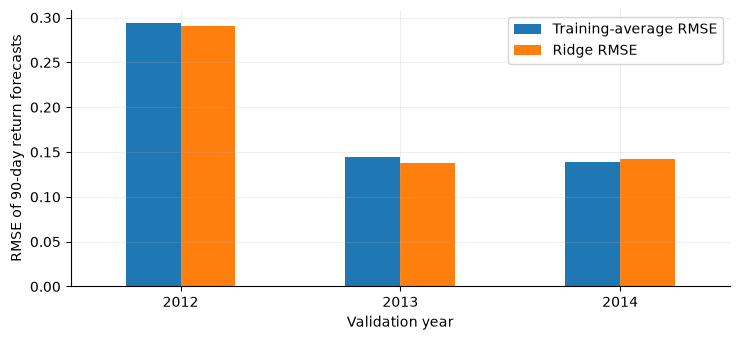

In [4]:
mean_pipeline = make_pipeline(
    DummyRegressor(strategy="mean"),
    numeric_features=feature_names,
    include_sector=False,
)
mean_validation_scores = cross_val_score(
    mean_pipeline,
    search_features,
    search_targets,
    cv=folds,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)
best_result_index = search.best_index_
ridge_validation_errors = [
    -search_results.loc[best_result_index, f"split{fold_index}_test_score"]
    for fold_index in range(len(folds))
]
fold_comparison = pd.DataFrame(
    {
        "Validation year": VALIDATION_YEARS,
        "Training-average RMSE": -mean_validation_scores,
        "Ridge RMSE": ridge_validation_errors,
    }
)
display(fold_comparison)

figure, axis = plt.subplots(figsize=(7.5, 3.5))
fold_comparison.set_index("Validation year").plot.bar(ax=axis)
axis.set_ylabel("RMSE of 90-day return forecasts")
axis.tick_params(axis="x", labelrotation=0)
figure.tight_layout()
plt.show()
plt.close(figure)


## Later development check on 2015

The selected pipeline is refitted on all search rows, whose outcomes
finished before the first 2015 signal. It then predicts every eligible
2015 row. Prediction scoring uses rows with observable 90-day outcomes.
Rows whose exits extend beyond the data boundary retain their predictions
and missing targets. Future outcome availability is used only for scoring.

RMSE, MAE and R-squared describe return-prediction accuracy. Mean daily
rank IC is the average same-date Spearman correlation between forecasts
and realized returns. It describes cross-sectional stock ranking.
Overlapping outcomes make these observations dependent through time.


,Model,RMSE,MAE,R2,mean_daily_rank_IC,IC_dates
0,Training average,0.186707,0.110266,-0.020286,NaN,0.0
1,Ridge,0.184276,0.113195,0.006106,0.190875,189.0


,Eligible signals,Scorable outcomes,Unavailable outcomes,Last scorable signal
0,7027,5353,1674,2015-10-01


momentum_63       -0.034182
momentum_252_21   -0.029189
momentum_21       -0.006501
drawdown_252       0.037733
volatility_63      0.043744
Name: Ridge coefficient, dtype: float64

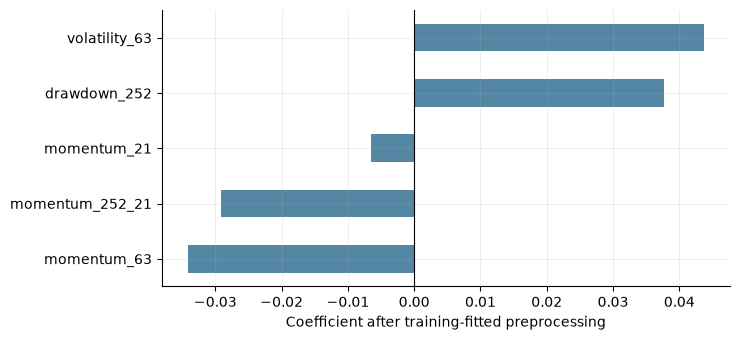

In [5]:
ridge_model = search.best_estimator_
mean_model = clone(mean_pipeline).fit(search_features, search_targets)
holdout_predictions = holdout[
    ["date", "symbol", "entry_date", "label_end", "target"]
].copy()
holdout_predictions["ridge_prediction"] = ridge_model.predict(
    holdout[feature_names]
)
holdout_predictions["training_mean_prediction"] = mean_model.predict(
    holdout[feature_names]
)
assert np.isfinite(holdout_predictions["ridge_prediction"]).all()
assert len(holdout_predictions) == len(holdout)

observable_outcomes = holdout["target"].notna()
scored_holdout = holdout.loc[observable_outcomes]
metric_records = []
for model_name, prediction_column in [
    ("Training average", "training_mean_prediction"),
    ("Ridge", "ridge_prediction"),
]:
    metrics = prediction_metrics(
        scored_holdout,
        holdout_predictions.loc[observable_outcomes, prediction_column],
    )
    metric_records.append({"Model": model_name, **metrics.to_dict()})

holdout_metrics = pd.DataFrame(metric_records)
display(holdout_metrics)
display(
    pd.DataFrame(
        {
            "Eligible signals": [len(holdout)],
            "Scorable outcomes": [int(observable_outcomes.sum())],
            "Unavailable outcomes": [int((~observable_outcomes).sum())],
            "Last scorable signal": [scored_holdout["date"].max()],
        }
    )
)

transformed_names = ridge_model["preprocess"].get_feature_names_out()
coefficients = pd.Series(
    ridge_model["model"].coef_,
    index=[name.removeprefix("numeric__") for name in transformed_names],
    name="Ridge coefficient",
).sort_values()
display(coefficients)
figure, axis = plt.subplots(figsize=(7.5, 3.5))
coefficients.plot.barh(ax=axis, color="#5487a4")
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel("Coefficient after training-fitted preprocessing")
figure.tight_layout()
plt.show()
plt.close(figure)


## Interpretation and next development decisions

These tables assess the first classroom experiment. Compare validation
and 2015 results with the training-average forecast before deciding
whether the additional price information helps. The coefficient plot
shows associations conditional on the other features and the chosen
preprocessing.

The classroom sample has only 30 stocks. Feature choices and penalty
selection still need development-period validation on the full homework
universe. Portfolio performance will depend on the trading rules,
transaction costs, cash availability and the backtest's handling of
positions and missing prices.
